### Market Structure Multi-Scale Analysis V3

In [32]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import pywt
import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import fisher_exact
from sklearn.metrics import roc_auc_score
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)
from sklearn.feature_selection import (
    mutual_info_regression
)

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '1950-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

In [4]:
def get_fred_timeseries_data(
    observation_start: str,
    observation_end: str,
    series_mapping: dict[str, str] | None = None,
    frequency: str | None = None,
    aggregation_method: str | None = None,
) -> dict[str, pd.DataFrame]:
    observation_start = observation_start
    observation_end = observation_end
    base_fred_params = {
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": observation_start,
        "observation_end": observation_end,
        "frequency": frequency or "m",
        "aggregation_method": aggregation_method or "avg",
    }
    fred_dfs = {}
    for series_id, series_name in series_mapping.items():
        fred_params = base_fred_params.copy()
        fred_params["series_id"] = series_id
        fred_res = requests.get(fred_url, params=fred_params)
        fred_df = pd.DataFrame(fred_res.json()["observations"]).assign(**{
            "date": lambda df: pd.to_datetime(df["date"]),
            "value": lambda df: pd.to_numeric(df["value"], errors="coerce"),
            "interest_rate_type": series_name,
        })
        fred_dfs[series_name] = fred_df
        time.sleep(5)
        
    return fred_dfs

In [5]:
def delete_column(df):
    df = df.drop(columns=['realtime_start', 'realtime_end', 'interest_rate_type'])
    return df

#### S&P500(均等加重)時系列を取得

In [6]:
spxew_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^SPXEW",
    market=None,
    series_name="SPXEW"
))
spxew_df.tail()

取得件数: 4988


,value
date,
2026-10-22,8774.019531
2026-10-23,8841.269531
2026-10-26,8772.370117
2026-10-27,8802.639648
2026-10-28,8809.419922


#### S&P500(時価総額加重平均)時系列を取得

In [7]:
sp500_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
    series_name="GSPC"
))
sp500_df.tail()

取得件数: 19358


,value
date,
2026-10-22,7694.620117
2026-10-23,7637.180176
2026-10-26,7639.700195
2026-10-27,7699.470215
2026-10-28,7735.560059


#### Nasdaq100(均等加重)時系列を取得

In [8]:
ndxe_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^NDXE",
    market=None,
    series_name="NDXE"
))
ndxe_df.tail()

取得件数: 5149


,value
date,
2026-10-22,9974.679688
2026-10-23,9893.769531
2026-10-26,9917.309570
2026-10-27,10010.910156
2026-10-28,10064.759766


#### Nasdaq100(時価総額加重平均)時系列を取得

In [9]:
qqq_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
    series_name="IXIC"
))
qqq_df.tail()

取得件数: 14050


,value
date,
2026-10-22,26308.410156
2026-10-23,25893.949219
2026-10-26,26026.869141
2026-10-27,26286.310547
2026-10-28,26541.609375


#### iShares iBoxx $ High Yield Corporate Bond ETF

In [10]:
hyg_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="HYG",
    market=None,
    series_name="HYG"
))
hyg_df.tail()

取得件数: 4920


,value
date,
2026-10-22,76.769997
2026-10-23,76.889999
2026-10-26,77.080002
2026-10-27,77.300003
2026-10-28,77.709999


#### iShares 7-10 Year Treasury Bond ETF (IEF)

In [11]:
ief_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="IEF",
    market=None,
    series_name="IEF"
))
ief_df.tail()

取得件数: 6102


,value
date,
2026-10-22,90.750000
2026-10-23,91.230003
2026-10-26,91.160004
2026-10-27,91.059998
2026-10-28,91.059998


#### Federal Funds Effective Rate (DFF)

In [12]:
dff_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFF": "federal_funds_effective_rate"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["federal_funds_effective_rate"]
dff_df["date"] = pd.to_datetime(dff_df["date"])
dff_df = dff_df.set_index("date")
dff_df = delete_column(dff_df)
dff_df.head()

,value
date,
1954-07-01,1.13
1954-07-02,1.25
1954-07-03,1.25
1954-07-04,1.25
1954-07-05,0.88


#### Market Yield on U.S. Treasury Securities at 2-Year Constant Maturity, Quoted on an Investment Basis (DGS2)

In [13]:
dgs2_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS2": "two_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["two_year_treasury_yield"]
dgs2_df["date"] = pd.to_datetime(dgs2_df["date"])
dgs2_df = dgs2_df.set_index("date")
dgs2_df = delete_column(dgs2_df)
dgs2_df.head()

,value
date,
1976-06-01,7.26
1976-06-02,7.23
1976-06-03,7.22
1976-06-04,7.12
1976-06-07,7.09


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis (DGS10)

In [14]:
dgs10_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS10": "ten_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["ten_year_treasury_yield"]
dgs10_df["date"] = pd.to_datetime(dgs10_df["date"])
dgs10_df = dgs10_df.set_index("date")
dgs10_df = delete_column(dgs10_df)
dgs10_df.head()

,value
date,
1962-01-02,4.06
1962-01-03,4.03
1962-01-04,3.99
1962-01-05,4.02
1962-01-08,4.03


#### U.S. Dollars to Australian Dollar Spot Exchange Rate (DEXUSAL)

In [15]:
dxy_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DEXUSAL": "DXY"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["DXY"]
dxy_df["date"] = pd.to_datetime(dxy_df["date"])
dxy_df = dxy_df.set_index("date")
dxy_df = delete_column(dxy_df)
dxy_df.tail()

,value
date,
2026-10-19,0.6981
2026-10-20,0.7004
2026-10-21,0.7026
2026-10-22,0.7020
2026-10-23,0.7037


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis, Inflation-Indexed (DFII10)

In [16]:
real_yield_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFII10": "real_10y"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["real_10y"]
real_yield_df["date"] = pd.to_datetime(real_yield_df["date"])
real_yield_df = real_yield_df.set_index("date")
real_yield_df = delete_column(real_yield_df)
real_yield_df.tail()

,value
date,
2026-10-21,2.76
2026-10-22,2.64
2026-10-23,2.66
2026-10-26,2.66
2026-10-27,2.64


#### ICE BofA US High Yield Index Option-Adjusted Spread (BAMLH0A0HYM2)

In [17]:
credit_spread_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLH0A0HYM2": "credit_spread"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["credit_spread"]
credit_spread_df["date"] = pd.to_datetime(credit_spread_df["date"])
credit_spread_df = credit_spread_df.set_index("date")
credit_spread_df = delete_column(credit_spread_df)
credit_spread_df.tail()

,value
date,
2026-10-21,3.27
2026-10-22,3.40
2026-10-23,3.38
2026-10-26,3.30
2026-10-27,3.18


#### ICE BofA AAA US Corporate Index Option-Adjusted Spread (BAMLC0A1CAAA)

In [18]:
aaa_oas_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A1CAAA": "AAA_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["AAA_OAS"]
aaa_oas_df["date"] = pd.to_datetime(aaa_oas_df["date"])
aaa_oas_df = aaa_oas_df.set_index("date")
aaa_oas_df = delete_column(aaa_oas_df)
aaa_oas_df.tail()

,value
date,
2026-10-21,0.42
2026-10-22,0.42
2026-10-23,0.44
2026-10-26,0.43
2026-10-27,0.42


#### ICE BofA BBB US Corporate Index Option-Adjusted Spread (BAMLC0A4CBBB)

In [19]:
bbb_oas_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A4CBBB": "BBB_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["BBB_OAS"]
bbb_oas_df["date"] = pd.to_datetime(bbb_oas_df["date"])
bbb_oas_df = bbb_oas_df.set_index("date")
bbb_oas_df = delete_column(bbb_oas_df)
bbb_oas_df.tail()

,value
date,
2026-10-21,1.09
2026-10-22,1.11
2026-10-23,1.13
2026-10-26,1.12
2026-10-27,1.09


#### Federal Funds Effective Rate (FEDFUNDS)

In [20]:
ffer_df = get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"FEDFUNDS": "ff_rate"},
    frequency='m',
    aggregation_method=aggregation_method
)["ff_rate"]
ffer_df["date"] = pd.to_datetime(ffer_df["date"])
ffer_df = ffer_df.set_index("date")
ffer_df = delete_column(ffer_df)
ffer_df.tail()

,value
date,
2026-05-01,3.63
2026-06-01,3.63
2026-07-01,3.63
2026-08-01,3.63
2026-09-01,3.75


In [21]:
# ============================================================
# データ統合
# ============================================================
# 各データを共通フォーマットへ変換
df_list = [
    spxew_df.rename(columns={'value': "SPXEW"}),
    sp500_df.rename(columns={'value': "GSPC"}),
    ndxe_df.rename(columns={'value': "NDXE"}),
    qqq_df.rename(columns={'value': "IXIC"}),
    hyg_df.rename(columns={'value': "HYG"}),
    ief_df.rename(columns={'value': "IEF"}),
    dff_df.rename(columns={'value': "DFF"}),
    dgs2_df.rename(columns={'value': "DGS2"}),
    dgs10_df.rename(columns={'value': "DGS10"}),
    dxy_df.rename(columns={'value': "DXY"}),
    real_yield_df.rename(columns={'value': "DFII10"}),
    credit_spread_df.rename(columns={'value': "BAMLH0A0HYM2"}),
    aaa_oas_df.rename(columns={'value': "BAMLC0A1CAAA"}),
    bbb_oas_df.rename(columns={'value': "BAMLC0A4CBBB"}),
    ffer_df.rename(columns={'value': "FEDFUNDS"}),
]
# 日付で外部結合
market_df = pd.concat(df_list, axis=1, join="outer")
# 日付順にソート
market_df = market_df.sort_index()
# 重複日付除去
market_df = market_df[~market_df.index.duplicated(keep="first")]
# 欠損補完
market_df = market_df.ffill()
# 全列欠損行は削除
market_df = market_df.dropna(how="all")
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"V3_data_integration_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = market_df.copy()
df.to_csv(output_path)
# 確認
print("=" * 60)
print("Market Data Shape")
print(market_df.shape)
print("\nColumns")
print(market_df.columns.tolist())
print("\nHead")
display(market_df.head())
print("\nTail")
display(market_df.tail())

Market Data Shape
(27572, 15)

Columns
['SPXEW', 'GSPC', 'NDXE', 'IXIC', 'HYG', 'IEF', 'DFF', 'DGS2', 'DGS10', 'DXY', 'DFII10', 'BAMLH0A0HYM2', 'BAMLC0A1CAAA', 'BAMLC0A4CBBB', 'FEDFUNDS']

Head


/tmp/ipykernel_128/1528064943.py:23: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  market_df = pd.concat(df_list, axis=1, join="outer")


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
1949-11-17,NaN,15.960000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-18,NaN,16.139999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-21,NaN,16.070000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-22,NaN,16.150000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-23,NaN,16.190001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Tail


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
2026-10-24,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.00,0.7037,2.66,3.38,0.44,1.13,3.75
2026-10-25,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.00,0.7037,2.66,3.38,0.44,1.13,3.75
2026-10-26,8772.370117,7639.700195,9917.309570,26026.869141,77.080002,91.160004,3.88,4.68,5.00,0.7037,2.66,3.30,0.43,1.12,3.75
2026-10-27,8802.639648,7699.470215,10010.910156,26286.310547,77.300003,91.059998,3.88,4.70,4.99,0.7037,2.64,3.18,0.42,1.09,3.75
2026-10-28,8809.419922,7735.560059,10064.759766,26541.609375,77.709999,91.059998,3.88,4.70,4.99,0.7037,2.64,3.18,0.42,1.09,3.75


#### 1. Create Research Dataset

Build stationary explanatory variables and Wavelet targets.

In [22]:
# 研究データの準備
research_df = market_df.copy()
research_df.index = pd.to_datetime(research_df.index)
# Target
research_df["GSPC_LOG_RET"] = (np.log(research_df["GSPC"]).diff())
# 使用可能なデータの長さを2の累乗に揃える
research_df = research_df.dropna(
    subset=["GSPC_LOG_RET"]
)
# SWT
signal = research_df["GSPC_LOG_RET"].values
# 使用可能なデータの長さを2の累乗に揃えるための準備
usable_length = (2 ** int(np.floor(np.log2(len(signal)))))
# データを2の累乗の長さに揃える
research_df = research_df.iloc[-usable_length:].copy()
# 2の累乗に揃えた後の信号を取得
signal = research_df["GSPC_LOG_RET"].values
# SWTの最大レベルを設定
MAX_LEVEL = 6
# SWTを実行して詳細係数を取得
coeffs = pywt.swt(
    signal,
    wavelet="db4",
    level=MAX_LEVEL
)
# SWTの詳細係数をデータフレームに追加
for level_idx, (_, detail) in enumerate(coeffs, start=1):
    # レベルを計算
    level = (MAX_LEVEL - level_idx + 1)
    # データフレームに追加する列名を作成
    research_df[f"GSPC_D{level}"] = detail
# Stationary Features
research_df["HY_OAS_CHANGE"] = (
    research_df["BAMLH0A0HYM2"]
    .diff()
)
# BBBOASの変化量を計算
research_df["BBB_OAS_CHANGE"] = (
    research_df["BAMLC0A4CBBB"]
    .diff()
)
# HYGの対数リターンを計算
research_df["HYG_LOG_RET"] = (
    np.log(
        research_df["HYG"]
    )
    .diff()
)
# IEFの対数リターンを計算
research_df["IEF_LOG_RET"] = (
    np.log(
        research_df["IEF"]
    )
    .diff()
)
# 欠損値を削除
research_df = research_df.dropna()
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"1_Create_Research_Dataset_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
print("saved:", output_path)
# データの末尾を表示
research_df.tail()

saved: /workspace/data/1_Create_Research_Dataset_2026-10-29.csv


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,...,GSPC_D6,GSPC_D5,GSPC_D4,GSPC_D3,GSPC_D2,GSPC_D1,HY_OAS_CHANGE,BBB_OAS_CHANGE,HYG_LOG_RET,IEF_LOG_RET
date,,,,,,,,,,,,,,,,,,,,,
2026-10-24,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.00,0.7037,...,0.004161,-0.011807,-0.001282,-0.005600,-0.000736,0.004154,0.00,0.00,0.000000,0.000000
2026-10-25,8841.269531,7637.180176,9893.769531,25893.949219,76.889999,91.230003,3.88,4.69,5.00,0.7037,...,0.004188,-0.012053,-0.000031,-0.009059,0.000103,-0.001279,0.00,0.00,0.000000,0.000000
2026-10-26,8772.370117,7639.700195,9917.309570,26026.869141,77.080002,91.160004,3.88,4.68,5.00,0.7037,...,0.004161,-0.012088,0.001857,-0.008085,-0.001062,-0.004668,-0.08,-0.01,0.002468,-0.000768
2026-10-27,8802.639648,7699.470215,10010.910156,26286.310547,77.300003,91.059998,3.88,4.70,4.99,0.7037,...,0.004211,-0.012648,0.004107,-0.004853,-0.006653,0.007658,-0.12,-0.03,0.002850,-0.001098
2026-10-28,8809.419922,7735.560059,10064.759766,26541.609375,77.709999,91.059998,3.88,4.70,4.99,0.7037,...,0.004211,-0.012926,0.005012,-0.001061,-0.005244,-0.006343,0.00,0.00,0.005290,0.000000


# 2. Decile Analysis

Detect non-linear response of
Wavelet components to credit spread changes.

Note:
OAS change series contain many zeros.
Duplicate quantile edges are removed automatically.

In [23]:
# HY_OAS_CHANGEのデシル分析（重複する分位点を処理）
FEATURE = "HY_OAS_CHANGE"
results = []
# 各SWTレベルに対してHY_OAS_CHANGEのデシル分析を実行
for level in range(1, 7):
    # 対象のSWTレベルを設定
    target = f"GSPC_D{level}"
    # 対象のデータを抽出
    tmp = (research_df[[FEATURE, target]].dropna().copy())
    # Handle duplicate quantile edges
    tmp["bucket"] = pd.qcut(
        tmp[FEATURE],
        q=10,
        labels=False,
        duplicates="drop"
    )
    # デシルごとの統計量を計算
    summary = (
        tmp
        .groupby("bucket")[target]
        .agg(
            mean="mean",
            median="median",
            std="std",
            count="count"
        )
        .reset_index()
    )
    # 対象のSWTレベルを追加
    summary["target"] = target
    # 結果をリストに追加
    results.append(summary)
# リストに追加された各SWTレベルのデシル分析結果を結合
decile_df = pd.concat(results,ignore_index=True)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"2_Decile_Analysis_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
decile_df.to_csv(output_path)
print("saved:", output_path)
# データの末尾を表示
decile_df.tail()

saved: /workspace/data/2_Decile_Analysis_2026-10-29.csv


,bucket,mean,median,std,count,target
37,2,-0.000725,0.000260,0.006564,101,GSPC_D6
38,3,-0.000513,-0.000517,0.006418,427,GSPC_D6
39,4,-0.000768,-0.000103,0.006284,110,GSPC_D6
40,5,0.000109,-0.000477,0.007401,115,GSPC_D6
41,6,0.001543,0.000750,0.008040,102,GSPC_D6


#### 3. Decile Analysis Visualization

Mean response by quantile bucket

saved: /workspace/data/figures/3_Decile_Analysis_Visualization_1950-01-01_2026-10-29.png


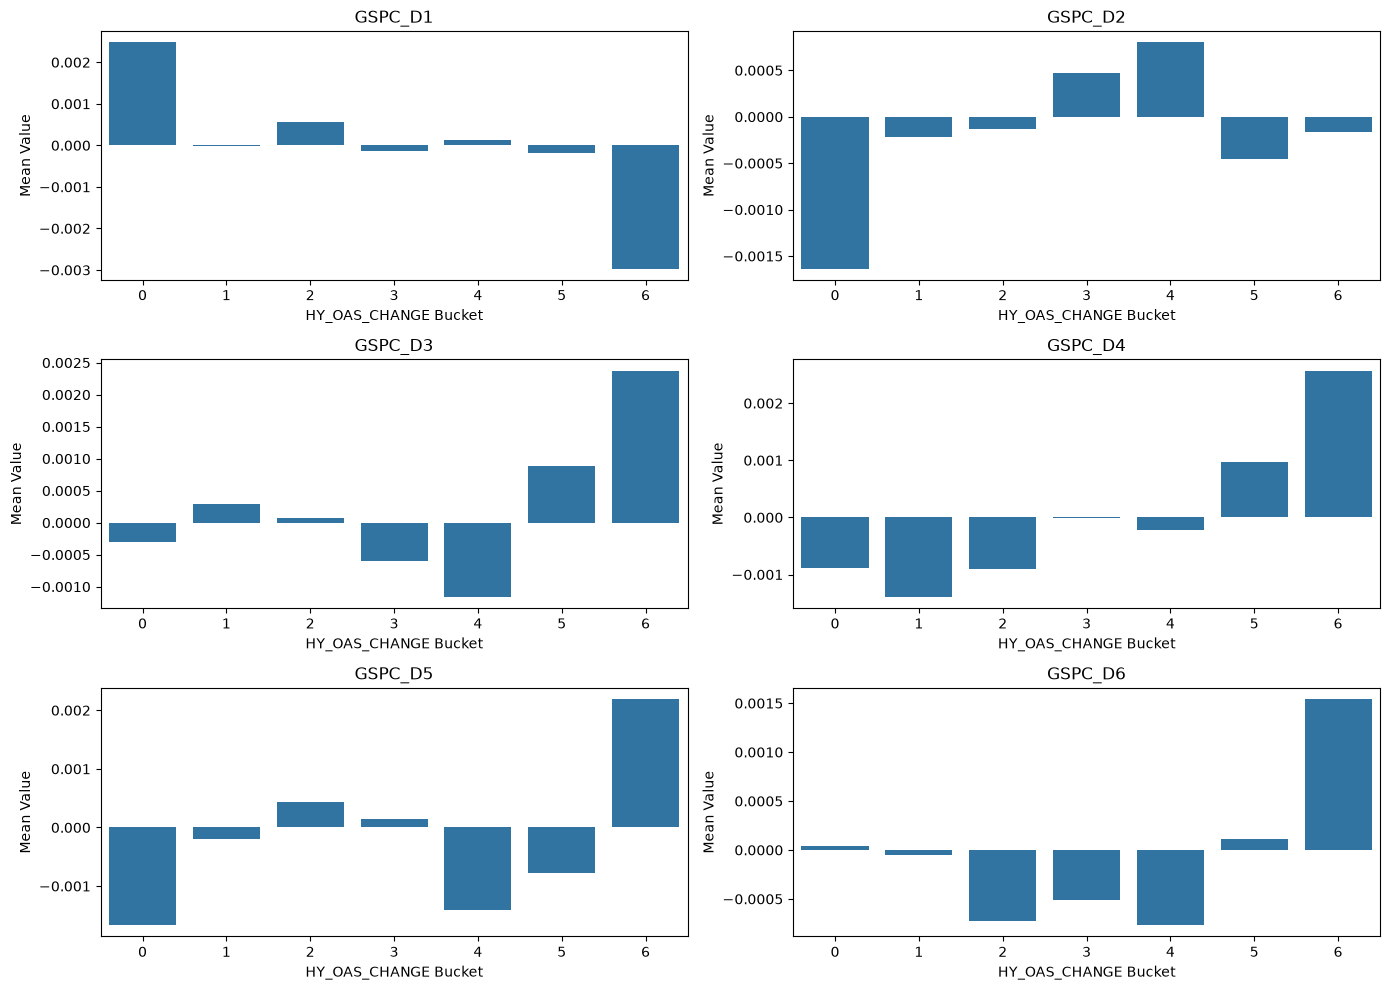

In [24]:
# HY_OAS_CHANGEのデシル分析を可視化（各SWTレベルごとに平均値を棒グラフで表示）
FEATURE = "HY_OAS_CHANGE"
# 各SWTレベルごとにHY_OAS_CHANGEのデシルごとの平均値を計算して棒グラフで表示
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
# インデックス指定を容易にするため、軸の配列を平坦化する。
axes = axes.flatten()
# 各SWTレベルのデシル分析結果を順番にプロットする。
for level in range(1, 7):
    # 対象のSWTレベルを設定
    target = f"GSPC_D{level}"
    # 対象のデータを抽出
    tmp = (
        research_df[[FEATURE, target]]
        .dropna()
        .copy()
    )
    # デシルの作成
    tmp["bucket"] = pd.qcut(
        tmp[FEATURE],
        q=10,
        labels=False,
        duplicates="drop"
    )
    # デシルごとの平均値を計算
    plot_df = (
        tmp
        .groupby("bucket")[target]
        .mean()
        .reset_index()
    )
    # 棒グラフを作成
    sns.barplot(
        data=plot_df,
        x="bucket",
        y=target,
        ax=axes[level - 1]
    )
    # グラフのタイトルを設定
    axes[level - 1].set_title(target)
    # X軸のラベルを設定
    axes[level - 1].set_xlabel(
        f"{FEATURE} Bucket"
    )
    # Y軸のラベルを設定
    axes[level - 1].set_ylabel("Mean Value")
# レイアウトを調整して表示
plt.tight_layout()
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"3_Decile_Analysis_Visualization_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
# グラフを表示
plt.show()

#### 4. Event Analysis

Compare:
- Large Tightening
- No Change
- Large Widening


In [26]:
# HY_OAS_CHANGEのイベント分析（GSPC_D6を対象）
FEATURE = "HY_OAS_CHANGE"
TARGET = "GSPC_D6"
# イベント分析の対象データを抽出
tmp = (
    research_df[[FEATURE, TARGET]]
    .dropna()
    .copy()
)
# イベント列を初期化（デフォルトはNO_CHANGE）
tmp["event"] = "NO_CHANGE"
# WIDENINGイベントを設定
tmp.loc[
    tmp[FEATURE]
    >= tmp[FEATURE].quantile(0.9),
    "event"
] = "WIDENING"
# TIGHTENINGイベントを設定
tmp.loc[
    tmp[FEATURE]
    <= tmp[FEATURE].quantile(0.1),
    "event"
] = "TIGHTENING"
# イベントごとの統計量を計算
event_summary = (
    tmp
    .groupby("event")[TARGET]
    .agg(
        mean="mean",
        median="median",
        std="std",
        count="count"
    )
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"4_Event_Analysis_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
event_summary.to_csv(output_path)
print("saved:", output_path)
# イベントごとの統計量を表示
event_summary

saved: /workspace/data/4_Event_Analysis_2026-10-29.csv


,mean,median,std,count
event,,,,
NO_CHANGE,-0.000449,-0.000315,0.006463,857
TIGHTENING,0.000042,-0.000179,0.006798,124
WIDENING,0.001526,0.001201,0.008065,113


In [29]:
# Spearman相関の計算
features = [
    "HY_OAS_CHANGE",
    "BBB_OAS_CHANGE",
    "HYG_LOG_RET",
    "IEF_LOG_RET",
]
results = []
# 各特徴量とターゲットの組み合わせに対してSpearman相関を計算
for feature in features:
    # 各レベルのターゲットに対してループ
    for level in range(1, 7):
        # ターゲット列を設定
        target = f"GSPC_D{level}"
        # 対象データを抽出
        tmp = (research_df[[feature, target]].dropna())
        # Spearman相関を計算
        corr, pvalue = spearmanr(
            tmp[feature],
            tmp[target]
        )
        # 計算結果をリストに追加
        results.append(
            {
                "feature": feature,
                "target": target,
                "spearman": corr,
                "pvalue": pvalue,
                "n": len(tmp),
            }
        )
# 計算結果をデータフレームに変換
spearman_df = pd.DataFrame(results)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"4_Spearman_correlation_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
spearman_df.to_csv(output_path)
print("saved:", output_path)
# Spearman相関の結果を相関係数でソートして表示
spearman_df.sort_values("spearman", ascending=False)

saved: /workspace/data/4_Spearman_correlation_2026-10-29.csv


,feature,target,spearman,pvalue,n
12,HYG_LOG_RET,GSPC_D1,0.161464,7.887712e-08,1094
9,BBB_OAS_CHANGE,GSPC_D4,0.144605,1.565345e-06,1094
3,HY_OAS_CHANGE,GSPC_D4,0.143815,1.786597e-06,1094
7,BBB_OAS_CHANGE,GSPC_D2,0.093583,1.944463e-03,1094
8,BBB_OAS_CHANGE,GSPC_D3,0.083645,5.635038e-03,1094
10,BBB_OAS_CHANGE,GSPC_D5,0.080028,8.092116e-03,1094
11,BBB_OAS_CHANGE,GSPC_D6,0.064830,3.202445e-02,1094
4,HY_OAS_CHANGE,GSPC_D5,0.057305,5.812099e-02,1094
1,HY_OAS_CHANGE,GSPC_D2,0.046221,1.265485e-01,1094
19,IEF_LOG_RET,GSPC_D2,0.042434,1.607479e-01,1094


#### 5. Spearman Heatmap

saved: /workspace/data/figures/5_Spearman_Correlation_1950-01-01_2026-10-29.png


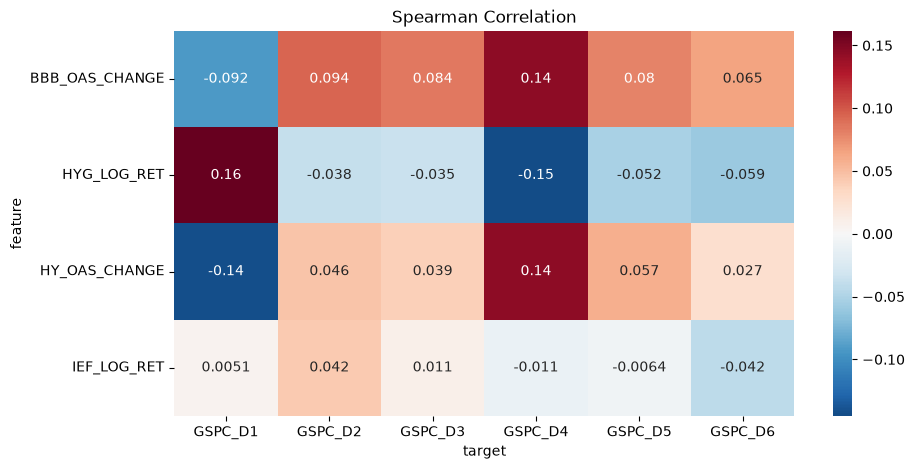

In [30]:
# Spearman相関のヒートマップを作成
heatmap_df = (
    spearman_df
    .pivot(
        index="feature",
        columns="target",
        values="spearman"
    )
)
# ヒートマップを作成するためのデータフレームを準備
plt.figure(figsize=(10, 5))
# ヒートマップを作成
sns.heatmap(
    heatmap_df,
    annot=True,
    cmap="RdBu_r",
    center=0
)
# ヒートマップのタイトルを設定
plt.title("Spearman Correlation")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"5_Spearman_Correlation_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
# グラフを表示
plt.show()

#### 6. Mutual Information

Detect non-linear dependency.

In [ ]:
# 特徴量とマルチスケールなターゲットとの間の相互情報を計算する
results = []
# 各特徴量と各マルチスケールターゲットの相互情報を計算する
for feature in features:
    # 各マルチスケールターゲットのレベルをループする
    for level in range(1, 7):
        # マルチスケールターゲットの列名を作成する
        target = f"GSPC_D{level}"
        # 特徴量とターゲットのデータを抽出し、欠損値を削除する
        tmp = (research_df[[feature, target]].dropna())
        # 特徴量とターゲットのデータをXとyに分ける
        X = tmp[[feature]]
        y = tmp[target]
        # 相互情報量を計算する
        mi = mutual_info_regression(X, y, random_state=42)[0]
        # 計算結果をリストに追加する
        results.append(
            {
                "feature": feature,
                "target": target,
                "mi": mi,
            }
        )
# 計算結果をデータフレームに変換する
mi_df = pd.DataFrame(results)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"6_Mutual_Information_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
mi_df.to_csv(output_path)
print("saved:", output_path)
# 相互情報量の高い順にソートする
mi_df.sort_values("mi", ascending=False)

saved: /workspace/data/6_Mutual_Information_2026-10-29.csv


,feature,target,mi
6,BBB_OAS_CHANGE,GSPC_D1,0.058658
12,HYG_LOG_RET,GSPC_D1,0.043305
14,HYG_LOG_RET,GSPC_D3,0.031025
10,BBB_OAS_CHANGE,GSPC_D5,0.024983
11,BBB_OAS_CHANGE,GSPC_D6,0.021317
1,HY_OAS_CHANGE,GSPC_D2,0.021184
3,HY_OAS_CHANGE,GSPC_D4,0.020114
8,BBB_OAS_CHANGE,GSPC_D3,0.019307
23,IEF_LOG_RET,GSPC_D6,0.008954
19,IEF_LOG_RET,GSPC_D2,0.007750


#### 7. Mutual Information Heatmap

In [ ]:
# 相互情報量のヒートマップを作成する
heatmap_df = (
    mi_df
    .pivot(
        index="feature",
        columns="target",
        values="mi"
    )
)
# ヒートマップを描画するためのデータフレームを作成する
plt.figure(figsize=(10, 5))
# ヒートマップを描画する
sns.heatmap(
    heatmap_df,
    annot=True,
    cmap="viridis"
)
# タイトルを設定する
plt.title("Mutual Information")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"7_Mutual_Information_Heatmap_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
# グラフを表示
plt.show()